# ANALYSIS NOTEBOOK FOR sales_data.csv

IMPORTING THE NECESSARY LIBRARIES: {Numpy, Pandas, MatplotLib, MissingNo}

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msg


CONVERTING sales_data.csv INTO A PANDAS DATAFRAME 

In [2]:
df=pd.read_csv(r'C:\Users\cogen\OneDrive\Documents\OPERATION_DOOMSDAY\sales_data.csv')
df.head()

,ad_spend,social_clicks,email_opens,revenue
0,1200,340.0,180,5400
1,1500,410.0,210,6800
2,800,220.0,120,3500
3,2200,590.0,310,9800
4,1750,480.0,250,7900


# DATA CLEANING

In [3]:
# Finding out Information about the data 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ad_spend       12 non-null     int64  
 1   social_clicks  11 non-null     float64
 2   email_opens    12 non-null     int64  
 3   revenue        12 non-null     int64  
dtypes: float64(1), int64(3)
memory usage: 512.0 bytes


In [4]:
# Result shows 11 non-null counts out of 12 which means one of the values in social_clicks is a NaN value

Missing Values

<Axes: >

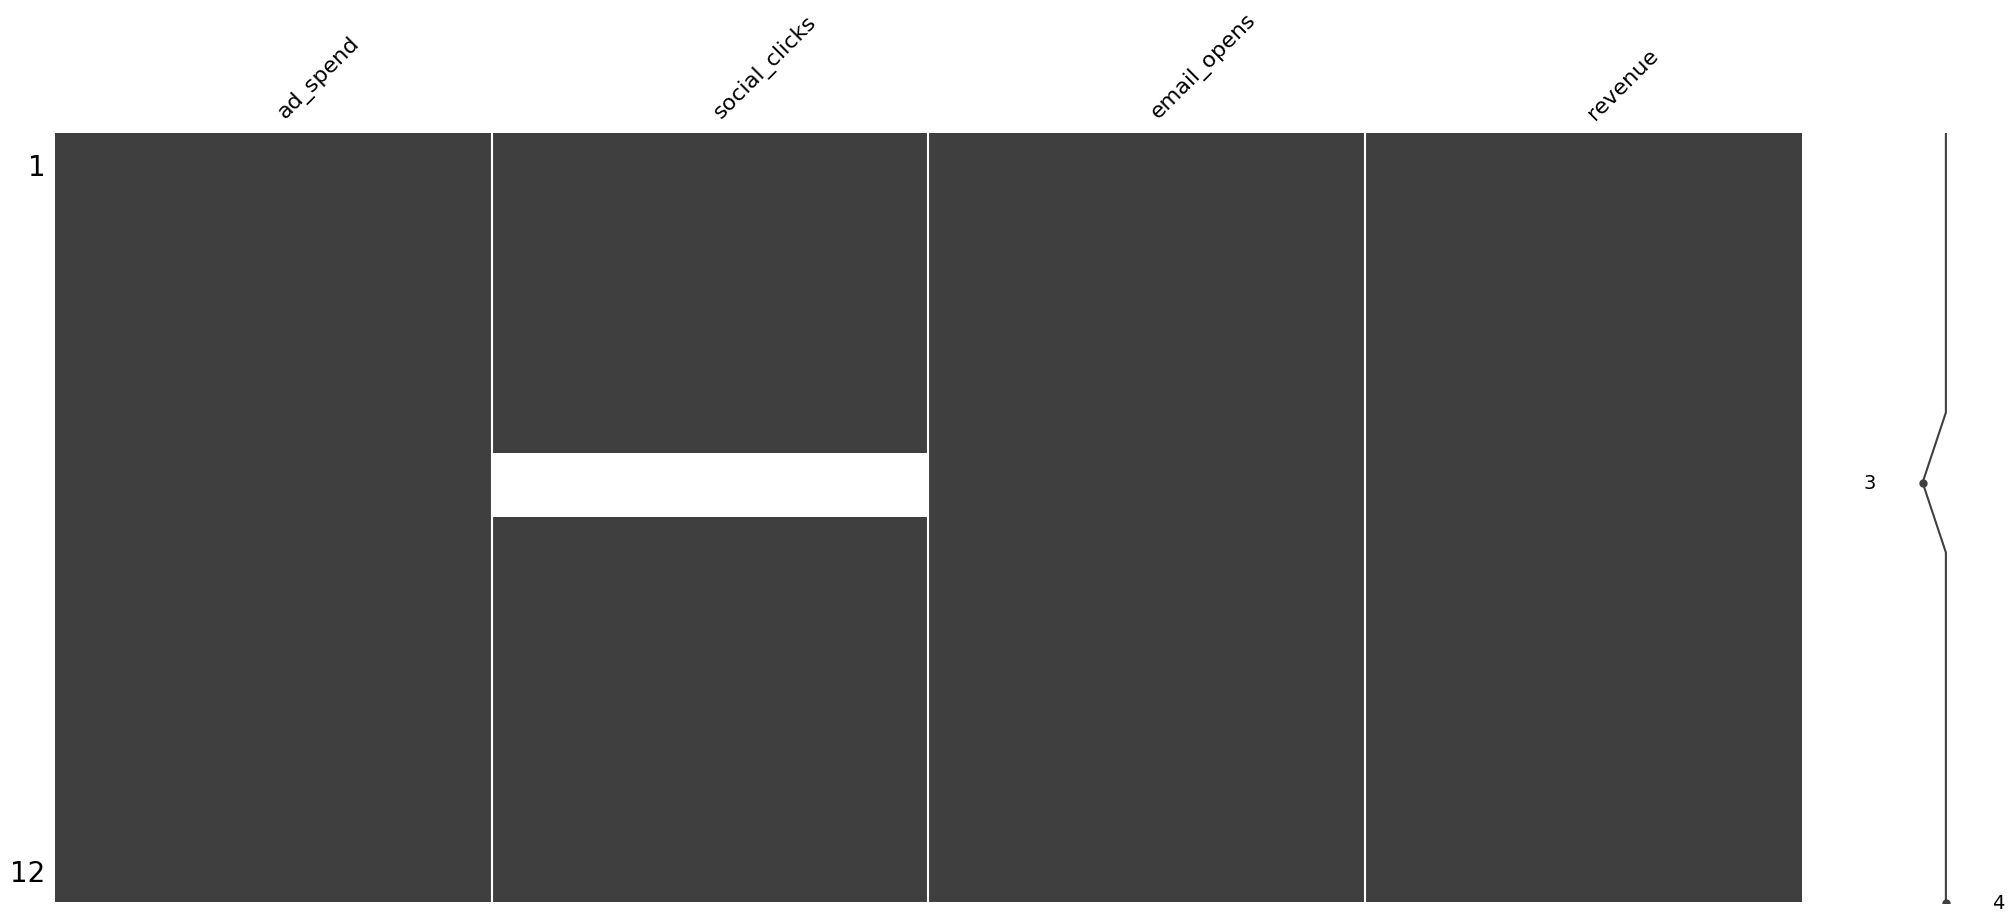

In [5]:
# Using the MissingNo matrix function to graphically locate missing (NaN) values in the DataFrame
msg.matrix(df)

In [6]:
# Missing Value Counts
df.isnull().sum()

ad_spend         0
social_clicks    1
email_opens      0
revenue          0
dtype: int64

In [7]:
# Results from the last command show there is one missing value in 'social_clicks' 
# Best fix is to fill the missing value with social_clicks median value

<Axes: >

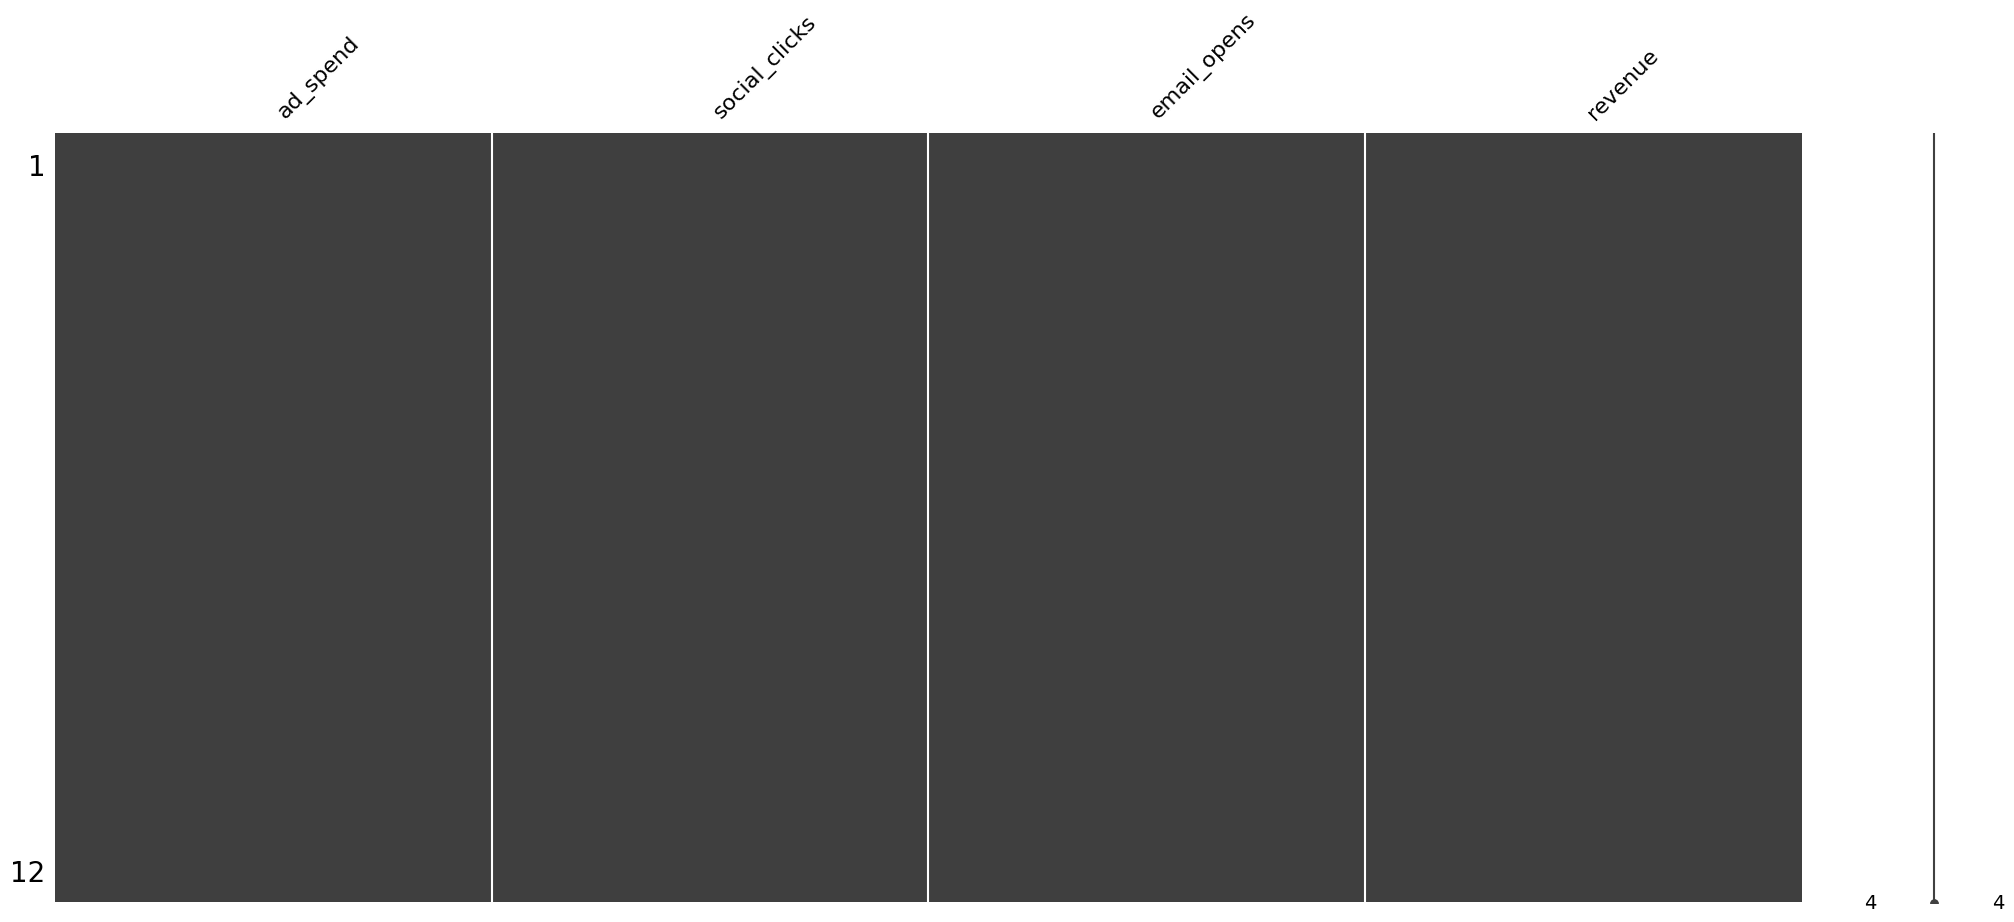

In [8]:
#Filling mising(NaN) values with Median value of the social_click
df.fillna(df['social_clicks'].median(), inplace=True)
msg.matrix(df)

In [9]:
# From the graphical representation it shows there are no NaN values in the DataFrame

Statistical Summary of the DataFrame

In [10]:
df.describe()

,ad_spend,social_clicks,email_opens,revenue
count,12.000000,12.000000,12.00000,12.000000
mean,1733.333333,480.833333,250.00000,7708.333333
std,699.458665,186.667343,100.88247,3085.879375
min,800.000000,220.000000,120.00000,3500.000000
25%,1175.000000,330.000000,175.00000,5275.000000
50%,1625.000000,480.000000,230.00000,7350.000000
75%,2250.000000,605.000000,317.50000,10000.000000
max,3000.000000,820.000000,440.00000,13200.000000


# VISUALIZATIONS

[Text(0.5, 1.0, 'Relationship between Ad Spend and Revenue'),
 Text(0.5, 0, 'Ad Spend'),
 Text(0, 0.5, 'Revenue')]

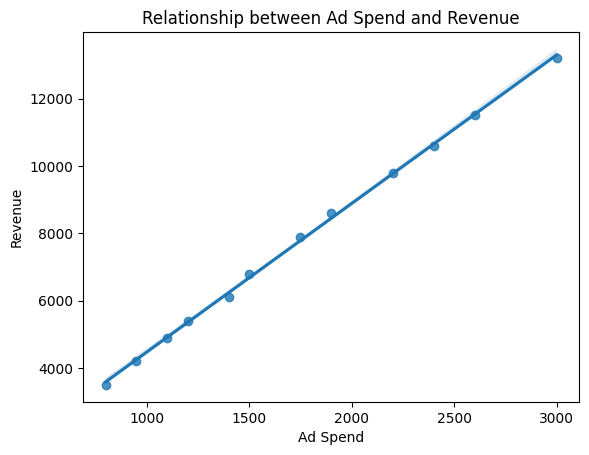

In [11]:
sns.regplot(data=df, x='ad_spend',y='revenue').set(title='Relationship between Ad Spend and Revenue',xlabel='Ad Spend', ylabel='Revenue')

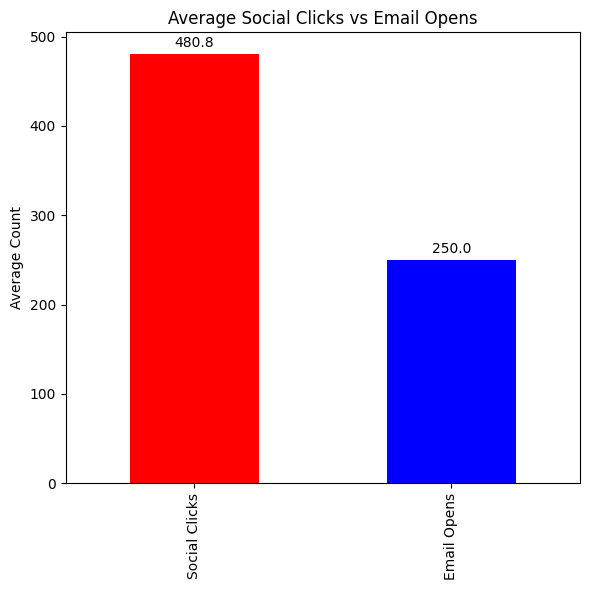

In [15]:
averages=df[['social_clicks','email_opens']].mean()
ax=averages.plot(kind='bar',color=['red','blue'],figsize=(6,6))
ax.set_title('Average Social Clicks vs Email Opens')
ax.set_ylabel('Average Count')
ax.set_xticklabels(['Social Clicks','Email Opens'])

ax.bar_label(ax.containers[0], fmt='%.1f', padding=3)

plt.tight_layout()
plt.show()